<a href="https://colab.research.google.com/github/Sam-Alvz/Proyecto-deteccion-spam-ia/blob/main/Actividad_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Instalación de librerías del ecosistema Hugging Face y evaluación
!pip install -q transformers datasets evaluate accelerate huggingface_hub scikit-learn pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00


In [ ]:
import torch
from huggingface_hub import notebook_login

# 1. Verificación del entorno GPU
if torch.cuda.is_available():
    print(f"GPU detectada y activa: {torch.cuda.get_device_name(0)}")
else:
    print("Atención: No se detectó GPU. Ve a Entorno de ejecución > Cambiar tipo de entorno de ejecución y selecciona T4 GPU.")

# 2. Autenticación en Hugging Face Hub
# Requiere un User Access Token con permiso de lectura (de tu cuenta de Hugging Face)
print("\nInicia sesión en Hugging Face:")
notebook_login()

GPU detectada y activa: Tesla T4

Inicia sesión en Hugging Face:


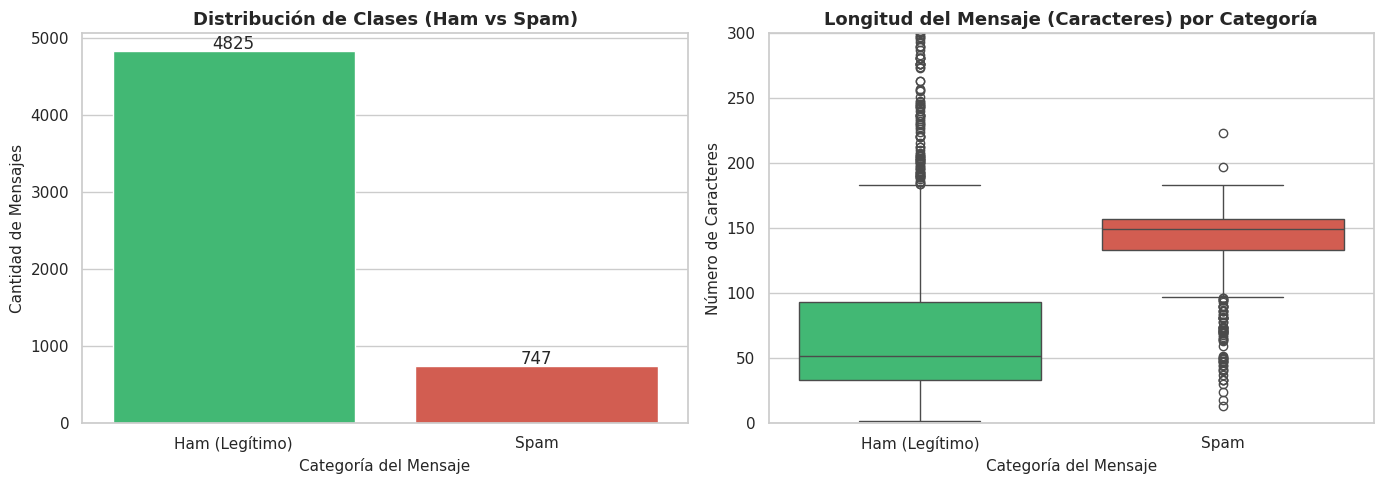

--- Resumen Estadístico de Longitud por Categoría ---
                 count    mean    std   min    50%    max
class_name                                               
Ham (Legítimo)  4825.0   71.48  58.44   2.0   52.0  910.0
Spam             747.0  138.67  28.87  13.0  149.0  223.0


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

# 1. Carga del conjunto de datos
try:
    raw_dataset = load_dataset("uciml/sms_spam")
except Exception:
    url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/sms.tsv"
    df_raw = pd.read_csv(url, sep="\t", header=None, names=["label_raw", "text"])
    df_raw["label"] = df_raw["label_raw"].map({"ham": 0, "spam": 1})
    from datasets import Dataset, DatasetDict

    dataset = Dataset.from_pandas(df_raw[["text", "label"]])
    raw_dataset = DatasetDict({"train": dataset})

# Convertir a DataFrame para análisis
df = pd.DataFrame(raw_dataset["train"])

# Métrica adicional para el EDA: Longitud del texto en caracteres
df["char_length"] = df["text"].apply(len)
df["class_name"] = df["label"].map({0: "Ham (Legítimo)", 1: "Spam"})

# 2. Configuración estética de las gráficas
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Distribución de Clases (Conteo)
sns.countplot(
    data=df,
    x="class_name",
    palette=["#2ecc71", "#e74c3c"],
    ax=axes[0],
    hue="class_name",
    legend=False,
)
axes[0].set_title(
    "Distribución de Clases (Ham vs Spam)", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Categoría del Mensaje", fontsize=11)
axes[0].set_ylabel("Cantidad de Mensajes", fontsize=11)

# Agregar las etiquetas de conteo sobre las barras
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 5),
        textcoords="offset points",
    )

# Gráfica 2: Comparación de Longitud de Texto por Categoría
sns.boxplot(
    data=df,
    x="class_name",
    y="char_length",
    palette=["#2ecc71", "#e74c3c"],
    ax=axes[1],
    hue="class_name",
    legend=False,
)
axes[1].set_title(
    "Longitud del Mensaje (Caracteres) por Categoría",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Categoría del Mensaje", fontsize=11)
axes[1].set_ylabel("Número de Caracteres", fontsize=11)
axes[1].set_ylim(0, 300)  # Limitar rango para apreciar mejor el comportamiento

plt.tight_layout()
plt.show()

# 3. Resumen estadístico
print("--- Resumen Estadístico de Longitud por Categoría ---")
print(
    df.groupby("class_name")["char_length"].describe().round(2)[
        ["count", "mean", "std", "min", "50%", "max"]
    ]
)

In [6]:
import time
import evaluate
import numpy as np
import pandas as pd
import torch
from transformers import pipeline

# 1. Muestra de evaluación de 500 registros del dataset
eval_df = df.sample(n=500, random_state=42).reset_index(drop=True)
texts = eval_df["text"].tolist()
true_labels = eval_df["label"].tolist()

# Cargar métricas de evaluación de Hugging Face
accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")

# Tres modelos diferentes específicos para detección de spam
models_config = [
    {
        "alias": "BERT-Tiny (mrm8488)",
        "repo": "mrm8488/bert-tiny-finetuned-sms-spam-detection",
    },
    {
        "alias": "DistilRoBERTa (SharpWoofer)",
        "repo": "SharpWoofer/distilroberta-sms-spam-detector",
    },
    {
        "alias": "RoBERTa-Base (roshana1s)",
        "repo": "roshana1s/spam-message-classifier",
    },
]

results_list = []
device = 0 if torch.cuda.is_available() else -1

print("--- INICIANDO EVALUACIÓN COMPARATIVA DE MODELOS ---\n")

for config in models_config:
    model_alias = config["alias"]
    model_repo = config["repo"]
    print(f"Evaluando: {model_alias} ({model_repo})...")

    try:
        classifier = pipeline(
            "text-classification",
            model=model_repo,
            device=device,
            truncation=True,
            max_length=512,
        )

        # Medición de latencia (tiempo total de inferencia)
        start_time = time.time()
        predictions_raw = classifier(texts)
        end_time = time.time()

        total_time = end_time - start_time
        avg_latency_ms = (total_time / len(texts)) * 1000

        # Normalización de etiquetas (Spam = 1, Ham = 0)
        predicted_labels = []
        for pred in predictions_raw:
            label_str = str(pred["label"]).upper()
            if "SPAM" in label_str or label_str in ["LABEL_1", "1", "POSITIVE"]:
                predicted_labels.append(1)
            else:
                predicted_labels.append(0)

        # Corrección si la salida viene invertida por el creador del repositorio
        test_acc = accuracy_metric.compute(
            predictions=predicted_labels, references=true_labels
        )["accuracy"]
        if test_acc < 0.40:
            predicted_labels = [1 - x for x in predicted_labels]

        # Cálculo de métricas
        acc = accuracy_metric.compute(
            predictions=predicted_labels, references=true_labels
        )["accuracy"]
        prec = precision_metric.compute(
            predictions=predicted_labels, references=true_labels
        )["precision"]
        rec = recall_metric.compute(
            predictions=predicted_labels, references=true_labels
        )["recall"]
        f1 = f1_metric.compute(
            predictions=predicted_labels, references=true_labels
        )["f1"]

        results_list.append(
            {
                "Modelo": model_alias,
                "Accuracy": round(acc, 4),
                "Precision": round(prec, 4),
                "Recall": round(rec, 4),
                "F1-Score": round(f1, 4),
                "Latencia Promedio (ms/msg)": round(avg_latency_ms, 2),
                "Tiempo Total (s)": round(total_time, 2),
            }
        )
        print(f"-> Finalizado correctamente en {round(total_time, 2)} segundos.\n")

    except Exception as e:
        print(f"Error procesando {model_alias}: {e}\n")

# 2. Imprimir tabla comparativa final
results_df = pd.DataFrame(results_list)
print("=================== TABLA COMPARATIVA DE DESEMPEÑO ===================")
print(results_df.to_string(index=False))

--- INICIANDO EVALUACIÓN COMPARATIVA DE MODELOS ---

Evaluando: BERT-Tiny (mrm8488) (mrm8488/bert-tiny-finetuned-sms-spam-detection)...


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

-> Finalizado correctamente en 1.46 segundos.

Evaluando: DistilRoBERTa (SharpWoofer) (SharpWoofer/distilroberta-sms-spam-detector)...


config.json:   0%|          | 0.00/752 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  328MB            

...

tokenizer_config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/999k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

-> Finalizado correctamente en 5.06 segundos.

=================== TABLA COMPARATIVA DE DESEMPEÑO ===================
                     Modelo  Accuracy  Precision  Recall  F1-Score  Latencia Promedio (ms/msg)  Tiempo Total (s)
        BERT-Tiny (mrm8488)     0.984     0.9655  0.9032    0.9333                        2.92              1.46
DistilRoBERTa (SharpWoofer)     1.000     1.0000  1.0000    1.0000                        6.21              3.10
   RoBERTa-Base (roshana1s)     0.994     0.9683  0.9839    0.9760                       10.11              5.06
